In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
rng = np.random.default_rng(42)
n = 40
uyku = rng.uniform(4, 9, n).round(1)
enerji = np.clip(20 + 10 * uyku + rng.normal(0, 4, n), 0, 100).round(1)
df = pd.DataFrame({"Uyku_Suresi": uyku, "Enerji_Puani": enerji})

In [4]:
df.head()

,Uyku_Suresi,Enerji_Puani
0,7.9,100.0
1,6.2,84.2
2,8.3,100.0
3,7.5,95.9
4,4.5,65.5


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Uyku_Suresi   40 non-null     float64
 1   Enerji_Puani  40 non-null     float64
dtypes: float64(2)
memory usage: 772.0 bytes


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Uyku_Suresi,40.0,6.665,1.450119,4.2,5.475,6.6,7.90,8.9
Enerji_Puani,40.0,85.595,12.619479,60.2,73.425,85.4,99.75,100.0


<Axes: xlabel='Uyku_Suresi', ylabel='Enerji_Puani'>

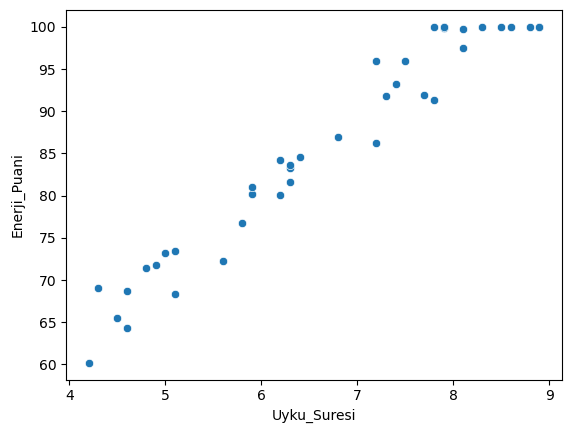

In [13]:
sns.scatterplot(x=df["Uyku_Suresi"],y=df["Enerji_Puani"],data=df)

In [14]:
X=df.drop("Enerji_Puani",axis=1)
y=df["Enerji_Puani"]

In [15]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [17]:
scaler = StandardScaler()

In [18]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
model = LinearRegression()

In [20]:
model.fit(X_train_scaled,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [21]:
model.coef_

array([11.74890569])

In [22]:
model.intercept_

np.float64(87.328125)

In [25]:
y_pred = model.predict(X_test_scaled)

In [26]:
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

In [29]:
print(f"\n[MODEL PERFORMANSI]")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {mse:.2f}")
print(f"R2 Score: {r2:.2f}")


[MODEL PERFORMANSI]
MAE: 3.16
RMSE: 14.28
R2 Score: 0.89


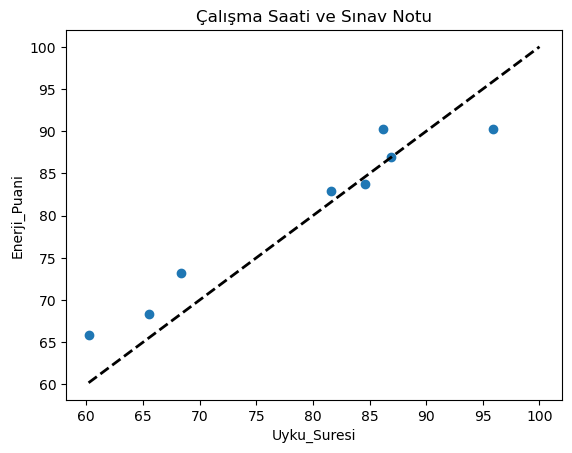

In [30]:
plt.scatter(y_test,y_pred)
plt.xlabel("Uyku_Suresi")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2) # İdeal 45 derece çizgisi
plt.ylabel("Enerji_Puani")
plt.title("Çalışma Saati ve Sınav Notu")
plt.show()